> 🔑 **SOLUTIONS NOTEBOOK**: instructor / self-check copy. Try the problems in `../notebooks/` first!

# 🌲 Lesson 02: Bagging & Random Forest

**Time:** ~2 hours  **Prerequisites:** Lessons 00–01

Last time we proved on paper that averaging many *diverse* models cuts variance. Today we stop talking and **build the thing**.

### 🎯 Learning goals
1. Explain the **bootstrap** and why a bootstrap sample contains ≈ 63.2% of the distinct rows.
2. Implement **bagging from scratch** in ~20 lines, and see it match scikit-learn.
3. Use the **out-of-bag (OOB)** rows as a *free* validation set.
4. Explain how a **Random Forest** de-correlates trees with `max_features`, and *measure* that effect.
5. Choose the main hyperparameters (`n_estimators`, `max_features`, `min_samples_leaf`, `max_depth`).
6. Know a random forest's weaknesses (it cannot extrapolate!) and run a first feature-importance analysis.

> 💡 **The puzzle from last lesson:** *every tree sees the same 2,400 houses, so how do we get 300 **different** trees?*
> Answer: we don't show them the same houses. We show each tree a *different random re-draw* of the data.

In [1]:
import sys; sys.path.append("../utils")          # lets us import the course helpers
from course_utils import *                       # load_housing(), check(), set_style(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt

set_style()
np.random.seed(SEED)
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor
from sklearn.pipeline import make_pipeline
from animations import bagging_animation

## 1 · The bootstrap: re-draw the data with replacement

Imagine your training set is a bag of $n$ numbered balls. A **bootstrap sample** is made by drawing a ball, writing down its number, **putting it back**, and repeating $n$ times.
Consequences: some balls appear twice or three times, and some never appear.

🔮 **Predict:** on average, what fraction of the *distinct* rows ends up in a bootstrap sample: 50%? 63%? 80%?

In [2]:
rng = np.random.default_rng(SEED)
data = np.arange(10)                         # a tiny "dataset": rows 0..9
for i in range(3):
    sample = rng.choice(data, size=len(data), replace=True)
    print(f"bootstrap {i+1}: {np.sort(sample)}   distinct rows: {len(np.unique(sample))}/10   never picked: {[int(v) for v in sorted(set(data) - set(sample))]}")

bootstrap 1: [0 0 0 2 4 4 6 6 7 8]   distinct rows: 6/10   never picked: [1, 3, 5, 9]
bootstrap 2: [1 4 5 5 7 7 7 7 8 9]   distinct rows: 6/10   never picked: [0, 2, 3, 6]
bootstrap 3: [1 3 4 4 5 5 6 7 8 9]   distinct rows: 8/10   never picked: [0, 2]


### 🧪 Worked Example 2.1: the 63.2% rule

For one particular row, the probability it is **not** picked in a single draw is $1 - \frac1n$. We make $n$ independent draws, so

$$P(\text{row never picked}) = \Big(1 - \frac1n\Big)^{n} \;\xrightarrow{\;n\to\infty\;}\; e^{-1} \approx 0.368.$$

So **≈ 36.8% of rows are left out** of any bootstrap sample (these are the **out-of-bag** rows: remember them, they become useful in a moment) and **≈ 63.2% are in**. Check numerically:

In [3]:
ns = [5, 10, 20, 50, 100, 500, 2000]
frac_in = []
for n in ns:
    fr = [len(np.unique(rng.integers(0, n, n))) / n for _ in range(400)]    # 400 bootstraps per n
    frac_in.append(np.mean(fr))

plt.figure(figsize=(7, 3.8))
plt.semilogx(ns, frac_in, "o-", label="simulated fraction of distinct rows")
plt.axhline(1 - np.exp(-1), color=PALETTE["orange"], ls="--", label="1 − 1/e ≈ 0.632")
plt.xlabel("dataset size n"); plt.ylabel("fraction of rows in the bootstrap sample"); plt.legend(); plt.show()
print("1 - 1/e =", round(1 - np.exp(-1), 4))

1 - 1/e = 0.6321


## 2 · Bagging from scratch

**B**ootstrap **agg**regat**ing** = bagging (Breiman, 1996). The recipe:

1. For $b = 1, \dots, B$: draw a bootstrap sample, train a (deliberately **deep, unpruned**) tree on it.
2. **Regression:** predict the *average* of the trees. **Classification:** *majority vote* (or average the probabilities).

Why deep trees? They have low bias and high variance: the perfect candidates for variance reduction by averaging (Lesson 01).

Here's the whole algorithm. Read it line by line; there's nothing hidden.

In [4]:
class MyBaggingRegressor:
    """Bagging in ~25 lines.  Also remembers which rows each tree saw, so we can compute OOB predictions."""

    def __init__(self, n_estimators=100, max_depth=None, random_state=0):
        self.n_estimators, self.max_depth, self.random_state = n_estimators, max_depth, random_state

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        self._X, self._y = np.asarray(X), np.asarray(y)
        n = len(self._y)
        self.trees_, self.in_bag_ = [], []
        for _ in range(self.n_estimators):
            idx = rng.integers(0, n, n)                                   # bootstrap: n draws WITH replacement
            tree = DecisionTreeRegressor(max_depth=self.max_depth, random_state=int(rng.integers(1_000_000_000)))
            self.trees_.append(tree.fit(self._X[idx], self._y[idx]))
            seen = np.zeros(n, dtype=bool); seen[idx] = True
            self.in_bag_.append(seen)                                     # which rows did this tree see?
        return self

    def predict(self, X):
        return np.mean([t.predict(np.asarray(X)) for t in self.trees_], axis=0)     # the committee's average

    def oob_prediction(self):
        """For each training row: average only the trees that did NOT train on it."""
        total, count = np.zeros(len(self._y)), np.zeros(len(self._y))
        for tree, seen in zip(self.trees_, self.in_bag_):
            out = ~seen
            total[out] += tree.predict(self._X[out]); count[out] += 1
        return total / np.maximum(count, 1)

First, the animation promised in Lesson 01: each orange line is one bootstrap-trained tree; the thick blue line is the running average.
Watch the average **calm down** as trees join the committee.

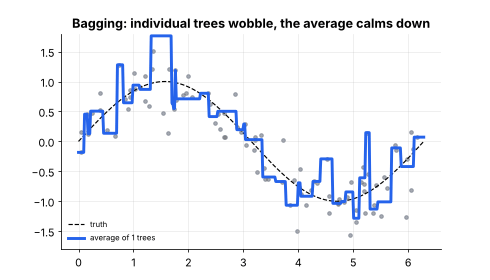

In [5]:
show_gif(bagging_animation())      # the plumbing is in utils/animations.py

Now let's test it on the housing data against a single tree and scikit-learn's own `BaggingRegressor`.
We pre-process once (impute + one-hot) so that we can feed plain NumPy arrays to our class.

In [6]:
X_train, X_test, y_train, y_test = get_housing_split()
prep = make_preprocessor(X_train)
Xtr, Xte = prep.fit_transform(X_train), prep.transform(X_test)       # fit on TRAIN only, then transform both
print("feature matrix:", Xtr.shape, "(houses × features after one-hot encoding)")

def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

with Timer() as t1:
    single = DecisionTreeRegressor(random_state=SEED).fit(Xtr, y_train)
with Timer() as t2:
    mine = MyBaggingRegressor(n_estimators=100, random_state=SEED).fit(Xtr, y_train)
with Timer() as t3:
    sk = BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, random_state=SEED, n_jobs=-1).fit(Xtr, y_train)

pd.DataFrame({
    "model": ["Single deep tree", "Bagging (our own class", "Bagging) scikit-learn"],
    "test RMSE": [rmse(y_test, single.predict(Xte)), rmse(y_test, mine.predict(Xte)), rmse(y_test, sk.predict(Xte))],
    "fit seconds": [t1.seconds, t2.seconds, t3.seconds],
}).round(2)

feature matrix: (2400, 35) (houses × features after one-hot encoding)


,model,test RMSE,fit seconds
0,Single deep tree,215.08,0.02
1,Bagging: our own class,120.63,1.96
2,Bagging: scikit-learn,124.74,1.41


Our 25-line class and the library agree (differences are just random-number luck), and both crush the single tree.
**You have now implemented a classic ensemble algorithm.** Take a screenshot: it's a milestone.

## 3 · Out-of-bag (OOB): a validation set you get for free

Each tree was trained on only ~63% of the rows. The other ~37% are **strangers** to that tree: exactly what a validation set is.
So for every training row we can average *only the trees that never saw it* and compare to the truth. No data set aside, no extra training.

### 🧪 Worked Example 2.2: OOB vs the real test set

In [7]:
oob_pred = mine.oob_prediction()
print(f"OOB RMSE (computed on the training rows, from unseen trees): {rmse(y_train, oob_pred):7.2f}")
print(f"Test RMSE (the real held-out set)                          : {rmse(y_test, mine.predict(Xte)):7.2f}")
print(f"Training RMSE (trees evaluated on rows they saw; dishonest): {rmse(y_train, mine.predict(Xtr)):7.2f}")

OOB RMSE (computed on the training rows, from unseen trees):  145.14
Test RMSE (the real held-out set)                          :  120.63
Training RMSE (trees evaluated on rows they saw; dishonest):   53.45


The **training** RMSE looks heroic and is meaningless (most trees *saw* those rows). The **OOB** RMSE is an honest estimate that lands in the same neighbourhood as the test RMSE: it's a bit more pessimistic because each row's OOB prediction averages only ~37% of the trees (a smaller committee).
In scikit-learn: `RandomForestRegressor(oob_score=True)` and then `.oob_prediction_`.

> ⚠️ **OOB is for quick tuning, not for final reporting.** When you tune many hyperparameters against OOB, you start overfitting *to the OOB estimate*. The final number must still come from data nothing ever touched (Lesson 06 / 07).

## 4 · From bagging to Random Forest: de-correlating the trees

Bagged trees are *still* highly correlated: on the same data, with the same strong features (`size_sqm`, `neighborhood`), every tree makes the **same first split**, and the same second split, and so on. Recall the floor from Lesson 01: $\rho\sigma^2$.

**Breiman's Random Forest (2001)** adds one idea to bagging:

> *At every split, consider only a random subset of the features (`max_features`).*

Strong features can't dominate every tree; trees are forced to find alternative routes to the answer. Individual trees get **slightly worse** (higher $\sigma^2$, more bias), but they become **much less correlated** (lower $\rho$): a very good trade.

### Seeing it on a 2-D toy problem
We'll classify the classic "two moons" data with three models and look at the decision regions.

In [8]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score

Xm, ym = make_moons(n_samples=400, noise=0.35, random_state=0)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.4, random_state=1)

moon_models = {
    "Single tree": DecisionTreeClassifier(random_state=0),
    "Bagged trees (100)": BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=0),
    "Random forest (100)": RandomForestClassifier(n_estimators=100, random_state=0),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, m) in zip(axes, moon_models.items()):
    m.fit(Xm_train, ym_train)
    acc = accuracy_score(ym_test, m.predict(Xm_test))
    plot_decision_boundary(m, Xm_train, ym_train, ax=ax, title=f"{name}\ntest accuracy {acc:.1%}")
plt.tight_layout(); plt.show()

single_acc = accuracy_score(ym_test, moon_models["Single tree"].predict(Xm_test))

The single tree's boundary is jagged: it carves little boxes around individual noisy points (**overfitting**). The ensembles produce smooth, sensible borders:
the average of many jagged boundaries *is* a smooth one. (On 2-D data bagging and forest look similar because there are only two features to choose from; the real difference shows up with many features, which we measure next.)

### 🧪 Worked Example 2.3: measuring ρ on the housing data

Plan: train forests with different `max_features`. For each one we measure
(a) the **average individual-tree error**, (b) the **average pairwise correlation** between the trees' predictions, and (c) the **forest's error**.
`max_features=1.0` means "every split sees all features": that's plain bagging.

🔮 **Predict:** as `max_features` shrinks, what happens to (a), (b) and (c)? Which of them should be U-shaped?

In [9]:
def mean_pairwise_corr(tree_preds):
    c = np.corrcoef(tree_preds)
    return (c.sum() - len(c)) / (len(c) * (len(c) - 1))

rows = []
for mf in [1.0, 0.7, 0.5, 0.33, 0.2, 0.1]:
    rf = RandomForestRegressor(n_estimators=100, max_features=mf, random_state=SEED, n_jobs=-1).fit(Xtr, y_train)
    tp = np.array([t.predict(Xte) for t in rf.estimators_])              # shape (100 trees, n_test)
    rows.append({"max_features": mf,
                 "avg single-tree RMSE": np.mean([rmse(y_test, p) for p in tp]),
                 "avg tree-to-tree correlation ρ": mean_pairwise_corr(tp),
                 "forest RMSE": rmse(y_test, tp.mean(axis=0))})
mf_table = pd.DataFrame(rows)
mf_table.round(3)

,max_features,avg single-tree RMSE,avg tree-to-tree correlation ρ,forest RMSE
0,1.00,216.037,0.789,124.419
1,0.70,217.669,0.777,121.575
2,0.50,221.166,0.762,118.136
3,0.33,229.104,0.733,117.773
4,0.20,232.723,0.711,113.400
5,0.10,256.417,0.632,119.921


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, color in zip(axes, ["avg single-tree RMSE", "avg tree-to-tree correlation ρ", "forest RMSE"],
                          [PALETTE["red"], PALETTE["purple"], PALETTE["blue"]]):
    ax.plot(mf_table["max_features"], mf_table[col], "o-", color=color)
    ax.set_xlabel("max_features (fraction of features per split)"); ax.set_title(col)
plt.tight_layout(); plt.show()

### 🔎 Reading the result
* **(a) individual trees get worse** as `max_features` shrinks (they're denied their best features).
* **(b) correlation drops**: the trees are becoming more diverse. Exactly the mechanism of the boxed formula.
* **(c) the forest** is the net effect of the two forces: lower ρ helps, higher single-tree error hurts. The sweet spot is *in the middle* (in our run around 0.2–0.33; a common starting range for regression is 0.3–0.5, and $\sqrt{p}$ is the classic default for classification). Push too far (0.1) and the trees become too weak: the U-shape appears.

> 💡 This is the **bias-variance-correlation tradeoff** in one table. Make a habit of finding the U-shape when you tune.

## 5 · How many trees? (Spoiler: more is never *worse*)

Unlike most hyperparameters, `n_estimators` can't cause overfitting: adding trees just refines the average.
It only costs time and memory. Let's trace the test error as the committee grows, by cumulatively averaging the trees of one 500-tree forest.

In [11]:
rf500 = RandomForestRegressor(n_estimators=500, max_features=0.4, random_state=SEED, n_jobs=-1).fit(Xtr, y_train)
all_preds = np.array([t.predict(Xte) for t in rf500.estimators_])
cum_avg = np.cumsum(all_preds, axis=0) / np.arange(1, 501)[:, None]
curve = np.sqrt(((cum_avg - y_test.values) ** 2).mean(axis=1))

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, 501), curve, color=PALETTE["blue"])
plt.xscale("log"); plt.xlabel("number of trees (log scale)"); plt.ylabel("test RMSE")
plt.title("Diminishing returns: most of the gain arrives in the first ~100 trees")
for k in (1, 10, 100, 500):
    plt.annotate(f"{k} trees\n{curve[k-1]:.0f}", (k, curve[k-1]), textcoords="offset points", xytext=(5, 12), fontsize=9)
plt.show()

**Practical rule:** 200–500 trees is plenty for most problems; use more only if the curve is still sloping and you have the time.

## 6 · The other hyperparameters (with OOB as our compass)

| hyperparameter | what it does | effect |
|---|---|---|
| `n_estimators` | number of trees | more = steadier, never overfits |
| `max_features` | features considered per split | lower → trees more diverse (the U-shape above) |
| `min_samples_leaf` | minimum rows in a leaf | **larger → smoother trees**, less variance, more bias |
| `max_depth` | depth cap | like `min_samples_leaf`, another way to regularise |
| `max_samples` | rows per bootstrap sample | smaller → faster, more diverse |
| `bootstrap`, `oob_score` | resample rows? compute OOB? | keep both on |

Let's sweep `min_samples_leaf` and track OOB error. We'll draw the *test* curve next to it only to confirm that OOB tells the same story (in real projects you'd rely on OOB or CV, never peek at the test set while tuning!).

In [12]:
rows = []
for leaf in [1, 2, 4, 8, 16, 32, 64]:
    rf = RandomForestRegressor(n_estimators=150, max_features=0.4, min_samples_leaf=leaf, oob_score=True,
                               random_state=SEED, n_jobs=-1).fit(Xtr, y_train)
    rows.append({"min_samples_leaf": leaf, "OOB RMSE": rmse(y_train, rf.oob_prediction_), "Test RMSE": rmse(y_test, rf.predict(Xte))})
leaf_table = pd.DataFrame(rows)

plt.figure(figsize=(7.5, 4))
plt.plot(leaf_table["min_samples_leaf"], leaf_table["OOB RMSE"], "o-", label="OOB RMSE (what we'd use to tune)")
plt.plot(leaf_table["min_samples_leaf"], leaf_table["Test RMSE"], "s--", label="Test RMSE (confirmation only)")
plt.xscale("log", base=2); plt.xlabel("min_samples_leaf"); plt.ylabel("RMSE"); plt.legend()
plt.title("OOB and test error move together"); plt.show()
leaf_table.round(2)

,min_samples_leaf,OOB RMSE,Test RMSE
0,1,137.62,116.54
1,2,140.30,124.44
2,4,147.36,134.00
3,8,156.33,143.87
4,16,170.19,155.53
5,32,184.22,170.52
6,64,204.35,190.19


**Surprise?** Here the error *rises* steadily with `min_samples_leaf`: `1` is best. That's not a rule, it's a property of this dataset: the signal is strong relative to the noise,
so extra smoothing only adds bias. On a **noisier** target (say, noisy sensor readings) larger leaves usually win. The lesson isn't "use leaf=1"; it's "**let the validation curve decide**, and expect different answers on different data."

## 7 · Random Forest vs. its cousins

* **Single tree**: high variance.
* **Bagging**: averages bootstrap trees; correlated trees.
* **Random Forest**: bagging + random feature subsets; the default powerhouse.
* **Extra-Trees** ("extremely randomised"): also picks the split *thresholds* at random: even more de-correlation, even faster, slightly more bias.

Let's put them side by side on the housing data.

In [13]:
contenders = {
    "Single tree":     DecisionTreeRegressor(random_state=SEED),
    "Bagging":         BaggingRegressor(DecisionTreeRegressor(), n_estimators=200, random_state=SEED, n_jobs=-1),
    "Random Forest":   RandomForestRegressor(n_estimators=200, max_features=0.4, random_state=SEED, n_jobs=-1),
    "Extra-Trees":     ExtraTreesRegressor(n_estimators=200, max_features=0.5, random_state=SEED, n_jobs=-1),
}
rows = []
for name, m in contenders.items():
    with Timer() as t:
        m.fit(Xtr, y_train)
    rows.append({"model": name, **regression_report(y_test, m.predict(Xte)), "fit_seconds": t.seconds})
results_table(rows).round(3)

,model,RMSE,MAE,R2,MAPE_%,fit_seconds
0,Extra-Trees,106.872,68.578,0.910,17.571,1.649
1,Random Forest,116.731,74.887,0.893,18.613,1.437
2,Bagging,123.411,78.759,0.880,18.838,3.008
3,Single tree,215.075,122.261,0.636,26.737,0.029


Extra-Trees wins here: choosing split thresholds at random de-correlates the trees even more, and because the true price surface is smooth, the extra randomness costs little bias.
That's a *dataset-specific* outcome, not a law, but it is a cheap model to try, so keep it in your toolbox.

## 8 · A weakness every practitioner must know: forests cannot extrapolate

A tree predicts the *average of training targets in a leaf*. Therefore its prediction can never be larger than the largest value (or smaller than the smallest) it saw in training.
Watch what happens when the future lies outside the past:

In [14]:
rng = np.random.default_rng(0)
x_tr = rng.uniform(0, 10, 200)
y_tr = 3 * x_tr + rng.normal(0, 2, 200)              # a clean upward trend
x_future = np.linspace(0, 15, 300)                    # ...but we are asked about x up to 15

from sklearn.linear_model import LinearRegression
lin = LinearRegression().fit(x_tr[:, None], y_tr)
rf_toy = RandomForestRegressor(n_estimators=200, random_state=0).fit(x_tr[:, None], y_tr)

plt.figure(figsize=(8, 4.2))
plt.scatter(x_tr, y_tr, s=10, color=PALETTE["gray"], label="training data")
plt.plot(x_future, 3 * x_future, "k--", label="true trend")
plt.plot(x_future, lin.predict(x_future[:, None]), color=PALETTE["green"], lw=2, label="linear regression")
plt.plot(x_future, rf_toy.predict(x_future[:, None]), color=PALETTE["blue"], lw=2, label="random forest")
plt.axvline(10, color="red", ls=":"); plt.text(10.2, 2, "end of training data", color="red")
plt.legend(); plt.title("Beyond the training range the forest goes flat"); plt.show()

⚠️ **Why this matters for the housing data:** prices inflate ~5% a year. If you train on 2019–2023 and predict 2024 listings,
a forest will *under*-predict, because 2024 prices lie beyond its experience. Remedies: model a **detrended** target (e.g. price per index),
add a linear component (stacking with a linear model, Lesson 05), or retrain regularly. We'll examine time-based validation in Lesson 06.

## 9 · A first look at feature importance

Random forests report **impurity-based importance (MDI)**: how much each feature reduced squared error across all splits, averaged over trees. It's free, so let's peek:

In [15]:
rf_final = RandomForestRegressor(n_estimators=300, max_features=0.4, min_samples_leaf=2, random_state=SEED, n_jobs=-1).fit(Xtr, y_train)
names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
imp = pd.Series(rf_final.feature_importances_, index=names).sort_values(ascending=False)

plt.figure(figsize=(8, 4.5))
imp.head(12)[::-1].plot.barh(color=PALETTE["blue"])
plt.xlabel("impurity-based importance (sums to 1 over all features)"); plt.title("Top 12 features by MDI importance")
plt.show()

Unsurprisingly, size, neighbourhood premium and distance dominate. **But beware:** MDI is biased toward high-cardinality and continuous features and
is computed on *training* data. In **Lesson 08** we will break it on purpose and learn the trustworthy alternatives (permutation importance, SHAP).

## 10 · Cheat-sheet: when to use bagging / random forest

✅ **Great when:** tabular data; you want a strong, low-effort baseline; many features; some noise; mixed types; you need OOB error quickly; parallel hardware.  
⚠️ **Watch out:** can't extrapolate; large models (many deep trees) → big memory/slow predictions; usually *beaten by tuned gradient boosting* on pure accuracy (Lessons 03–04).  
🎛️ **Defaults to start from:** `n_estimators=300`, `max_features=0.33–0.5` (regression) or `"sqrt"` (classification), `min_samples_leaf=1–5`.

### ✋ Check your understanding

Try to answer *out loud* before you open the answer. If you can't say it simply, you don't own it yet.

**Q1. Why do we use deep, unpruned trees as the base learners in bagging?**

<details><summary>Show answer</summary>

Bagging reduces **variance**, not bias. Deep trees have low bias and high variance, so they are the ideal raw material: averaging removes the variance and the low bias survives. Shallow trees are already low-variance, so there's little to gain.

</details>

**Q2. A colleague says: "I'll set n_estimators=10,000: more trees overfit less!" What's right and wrong in that sentence?**

<details><summary>Show answer</summary>

More trees never *increase* overfitting (they just stabilise the average), but returns diminish quickly after a few hundred and you pay in time/memory. It's harmless but usually wasteful. Overfitting in a forest is controlled by tree depth / leaf size, not by tree count.

</details>

**Q3. Lowering `max_features` makes each individual tree worse. Why can the *forest* still improve?**

<details><summary>Show answer</summary>

Because it lowers the correlation ρ between trees. Forest variance is $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$; a big drop in ρ can outweigh a modest rise in σ².

</details>

**Q4. Roughly what fraction of the training rows is out-of-bag for a given tree, and what do we use it for?**

<details><summary>Show answer</summary>

≈ 36.8% (1/e). Those rows are unseen by that tree, so predictions from trees that did not train on a row give a free, honest validation estimate (OOB error).

</details>

## 11 · Problems

### 🧩 Problem 02.1 ⭐: Measure the 63.2%

Write a function `bootstrap_indices(n, rng)` that returns the row indices of **one bootstrap sample** of size `n`.
Then, for `n = 1000`, average the **fraction of distinct rows** over 300 bootstrap samples and store it in `frac_unique`.

<details><summary>💡 Hint 1</summary>

A bootstrap draw is n integers chosen uniformly *with replacement* from 0…n−1: `rng.integers(0, n, n)`.

</details>

<details><summary>💡 Hint 2</summary>

`len(np.unique(idx)) / n` is the fraction of distinct rows in one sample; average over 300 samples with a list comprehension.

</details>

<details><summary>🆘 Stuck for real? Read this</summary>

Walk away for five minutes, re-read the lesson section above, then compare with the solutions notebook of the same name (`../solutions/`). Peeking is allowed -- but *type* the solution yourself, don't paste it.

</details>


In [16]:
def bootstrap_indices(n, rng):
    return rng.integers(0, n, n)

rng = np.random.default_rng(0)
frac_unique = np.mean([len(np.unique(bootstrap_indices(1000, rng))) / 1000 for _ in range(300)])

# ---- self-check ----
check("02.1", lambda: 0.62 < frac_unique < 0.645 and len(bootstrap_indices(50, np.random.default_rng(1))) == 50,
      "Expect ≈ 0.632 (that's 1 − 1/e). The function must return exactly n indices.", needs=[frac_unique])

✅ 02.1: correct -- nice work!


**✅ Solution walk-through (Problem 02.1)**

`rng.integers(0, n, n)` draws with replacement. The fraction of distinct rows converges to 1 − 1/e ≈ 0.632 quickly, which is why ~37% of rows are out-of-bag for every tree.

### 🧩 Problem 02.2 ⭐⭐: Bagged voting classifier

Using the moons data (`Xm_train`, `ym_train`, `Xm_test`, `ym_test`) implement bagging for **classification**:

* `fit_bagged_classifier(X, y, n_trees, seed)` → returns a list of `DecisionTreeClassifier`s, each trained on its own bootstrap sample.
* `predict_bagged(trees, X)` → majority vote (predict class 1 if more than half of the trees say 1).

Train 50 trees, then store the test accuracy in `bagged_acc`. (`single_acc`: the single tree's accuracy; is already defined.)

<details><summary>💡 Hint 1</summary>

Inside the loop: `idx = rng.integers(0, len(y), len(y))`, then `DecisionTreeClassifier(random_state=...).fit(X[idx], y[idx])`.

</details>

<details><summary>💡 Hint 2</summary>

For the vote: `votes = np.mean([t.predict(X) for t in trees], axis=0)` is the fraction of trees voting for class 1.

</details>

<details><summary>💡 Hint 3</summary>

`(votes > 0.5).astype(int)` gives the majority label. Finish with `accuracy_score(ym_test, predict_bagged(trees, Xm_test))`.

</details>

<details><summary>🆘 Stuck for real? Read this</summary>

Walk away for five minutes, re-read the lesson section above, then compare with the solutions notebook of the same name (`../solutions/`). Peeking is allowed -- but *type* the solution yourself, don't paste it.

</details>


In [17]:
def fit_bagged_classifier(X, y, n_trees=50, seed=0):
    rng = np.random.default_rng(seed)
    trees = []
    for _ in range(n_trees):
        idx = rng.integers(0, len(y), len(y))
        trees.append(DecisionTreeClassifier(random_state=int(rng.integers(1_000_000_000))).fit(X[idx], y[idx]))
    return trees

def predict_bagged(trees, X):
    votes = np.mean([t.predict(X) for t in trees], axis=0)
    return (votes > 0.5).astype(int)

trees = fit_bagged_classifier(Xm_train, ym_train, n_trees=50)
bagged_acc = accuracy_score(ym_test, predict_bagged(trees, Xm_test))

# ---- self-check ----
check("02.2", lambda: bagged_acc > 0.75 and bagged_acc >= single_acc - 0.01 and len(fit_bagged_classifier(Xm_train, ym_train, 7)) == 7,
      "Bagging should match or beat the single tree (≈ 80%) on this noisy data.", needs=[bagged_acc])

✅ 02.2: correct -- nice work!


**✅ Solution walk-through (Problem 02.2)**

Each tree sees a different bootstrap sample, so each draws a different jagged boundary; the vote smooths them. On noisy data like this you typically gain a few accuracy points over the single tree; on harder, higher-dimensional problems the gain is larger.

### 🧩 Problem 02.3 ⭐⭐: Honest OOB estimate

Train `RandomForestRegressor(n_estimators=200, max_features=0.4, oob_score=True, random_state=SEED, n_jobs=-1)` on `Xtr, y_train`.

* store the **OOB RMSE** (computed from `rf.oob_prediction_` against `y_train`) in `oob_rmse`,
* store the **test RMSE** in `test_rmse_rf`.

They should be in the same ballpark. *Reflection:* which one would you trust more to report to your manager, and why?

<details><summary>💡 Hint 1</summary>

Pass `oob_score=True` when constructing the forest; after `.fit`, the attribute `rf.oob_prediction_` holds one OOB prediction per training row.

</details>

<details><summary>💡 Hint 2</summary>

Use the helper `rmse(y_true, y_pred)` defined earlier in the lesson.

</details>

<details><summary>🆘 Stuck for real? Read this</summary>

Walk away for five minutes, re-read the lesson section above, then compare with the solutions notebook of the same name (`../solutions/`). Peeking is allowed -- but *type* the solution yourself, don't paste it.

</details>


In [18]:
rf = RandomForestRegressor(n_estimators=200, max_features=0.4, oob_score=True, random_state=SEED, n_jobs=-1).fit(Xtr, y_train)
oob_rmse = rmse(y_train, rf.oob_prediction_)
test_rmse_rf = rmse(y_test, rf.predict(Xte))

# ---- self-check ----
check("02.3", lambda: 80 < oob_rmse < 200 and 80 < test_rmse_rf < 200 and abs(oob_rmse - test_rmse_rf) / test_rmse_rf < 0.30,
      "Both should be roughly 110-150 and within ~30% of each other.", needs=[oob_rmse, test_rmse_rf])

✅ 02.3: correct -- nice work!


**✅ Solution walk-through (Problem 02.3)**

OOB (≈ 140) is a bit pessimistic compared with the test RMSE (≈ 120) (each OOB prediction averages only ~37% of the trees) and it's computed on a different set of rows, so some gap is natural. Report the **test** RMSE: it comes from rows that played no role in training *or* tuning.

### 🧩 Problem 02.4 ⭐⭐⭐: Tune max_features without touching the test set

For `max_features` in `[0.2, 0.33, 0.5, 0.75, 1.0]`, fit a `RandomForestRegressor(n_estimators=150, min_samples_leaf=2, oob_score=True, ...)` and record the **OOB RMSE**.

* store the results in a dict `oob_by_mf` (`{max_features: oob_rmse}`),
* pick the best value (lowest OOB RMSE) → `best_mf`,
* then refit with `best_mf` and store its **test** RMSE in `chosen_test_rmse`.

<details><summary>💡 Hint 1</summary>

Loop over the list; inside, fit the forest and compute `rmse(y_train, rf.oob_prediction_)`.

</details>

<details><summary>💡 Hint 2</summary>

`best_mf = min(oob_by_mf, key=oob_by_mf.get)` returns the key with the smallest value.

</details>

<details><summary>💡 Hint 3</summary>

Refit once more with `max_features=best_mf` (you can reuse the fitted forest from the loop if you store it) and evaluate on `Xte`.

</details>

<details><summary>🆘 Stuck for real? Read this</summary>

Walk away for five minutes, re-read the lesson section above, then compare with the solutions notebook of the same name (`../solutions/`). Peeking is allowed -- but *type* the solution yourself, don't paste it.

</details>


In [19]:
oob_by_mf, fitted = {}, {}
for mf in [0.2, 0.33, 0.5, 0.75, 1.0]:
    rf = RandomForestRegressor(n_estimators=150, min_samples_leaf=2, max_features=mf, oob_score=True,
                               random_state=SEED, n_jobs=-1).fit(Xtr, y_train)
    oob_by_mf[mf], fitted[mf] = rmse(y_train, rf.oob_prediction_), rf

best_mf = min(oob_by_mf, key=oob_by_mf.get)
chosen_test_rmse = rmse(y_test, fitted[best_mf].predict(Xte))

# ---- self-check ----
check("02.4", lambda: len(oob_by_mf) == 5 and best_mf == min(oob_by_mf, key=oob_by_mf.get) and chosen_test_rmse < 140,
      "Fill `oob_by_mf` with 5 entries; `best_mf` must be the key with the lowest OOB RMSE; the test RMSE should be below 140.",
      needs=[best_mf, chosen_test_rmse])

✅ 02.4: correct -- nice work!


**✅ Solution walk-through (Problem 02.4)**

Choosing hyperparameters with **OOB** (not test) keeps the test set clean. In our run OOB RMSE is flat-ish (≈ 141–144 across all five values) with the minimum near 0.33: a middle value, in line with Section 4. Notice how *small* the differences are: tuning `max_features` is worth a few percent, not a revolution. Be suspicious of anyone who claims a huge gain from it.

In [20]:
scoreboard()

Scoreboard: 4 solved, 0 to fix, 0 not attempted
   ✅ 02.1
   ✅ 02.2
   ✅ 02.3
   ✅ 02.4


## 🏁 Recap

* **Bootstrap** = sample with replacement → ≈ 63.2% distinct rows in, ≈ 36.8% out-of-bag.
* **Bagging** = average many deep trees trained on bootstrap samples → **cuts variance**.
* **OOB** rows provide a free validation estimate (good for tuning, not for the final report).
* **Random Forest** = bagging + `max_features` → trees become **less correlated** (we measured ρ falling).
* More trees never hurt; control overfitting with `min_samples_leaf` / `max_depth`.
* Forests **cannot extrapolate** beyond the training target range.

### ➡️ Next up: **Lesson 03: Boosting**
Bagging builds trees *in parallel and independently*. What if each new tree were built to **fix the mistakes of the ones before it**?
That single change gives us AdaBoost, then Gradient Boosting, and ultimately XGBoost.